# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [184]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [185]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [186]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [187]:
import random

numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
print("before set_seed")

print("First rand int:", random.randint(1,100))
random.shuffle(numbers)
print("First shuffled list:", numbers)

print("Second rand int:", random.randint(1,100))
numbers = list(range(10))
random.shuffle(numbers)
print("Second shuffled list:", numbers)

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ окремим генеруванням
print("\nafter set_seed")

set_seed()
print("First rand int:", random.randint(1,100))
numbers = list(range(10))
random.shuffle(numbers)
print("First shuffled list:", numbers)

set_seed()
print("Second rand int:", random.randint(1,100))
numbers = list(range(10))
random.shuffle(numbers)
print("Second shuffled list:", numbers)

# TODO: тепер ще двічі без проміжних викликів set_seed()
print("\nwithout intermediate set_seed")

print("First rand int:", random.randint(1,100))
numbers = list(range(10))
random.shuffle(numbers)
print("First shuffled list:", numbers)

print("Second rand int:", random.randint(1,100))
numbers = list(range(10))
random.shuffle(numbers)
print("Second shuffled list:", numbers)

before set_seed
First rand int: 4
First shuffled list: [7, 6, 2, 9, 0, 5, 1, 8, 3, 4]
Second rand int: 5
Second shuffled list: [6, 7, 2, 9, 5, 4, 8, 3, 1, 0]
Seed зафіксовано: 42

after set_seed
First rand int: 82
First shuffled list: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Second rand int: 82
Second shuffled list: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

without intermediate set_seed
First rand int: 76
First shuffled list: [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
Second rand int: 92
Second shuffled list: [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


*Після виклику set_seed() скидається стан генератора псевдовипадкових чисел до вказаної фіксованої початкової точки (seed = 42 у нашому випадку). У результатах це проявляється тим, що після кожного такого скидання генератор починає свою роботу з початку. Тому всі наступні дані та дії, які генерує бібліотека random (числа та перестановки), повністю дублюються, тобто стають однаковими.*

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [188]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [189]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [190]:
import numpy as np

# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [191]:
import numpy as np

# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [192]:
import numpy as np

# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(identity.ndim)

print(random_ints)
print(random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
2
[[6 3 7]
 [4 6 9]
 [2 6 7]]
2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [193]:
import numpy as np

scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [194]:
import numpy as np

arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = np.sum(matrix, axis=1)
col_sums = np.sum(matrix, axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [195]:
import pandas as pd

df = pd.DataFrame({
    'student': ['Ivan Ivanov', 'Sergiy Dub', 'Andrew Smith', 'John Doe', 'Rose Black', 'Jimmy Stone', 'Ashley Wood', 'Rick Fisher'],
    'score': [65, 70, 75, 90, 88, 100, 78, 67]
}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df.query('score > 80').sort_values('score', ascending=False)
print(top)


       student  score
5  Jimmy Stone    100
3     John Doe     90
4   Rose Black     88


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [196]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = df["score"].apply(lambda x: 'A' if x >= 90 else ('B' if x >= 75 else 'C'))
print(df)


        student  score grade
0   Ivan Ivanov     65     C
1    Sergiy Dub     70     C
2  Andrew Smith     75     B
3      John Doe     90     A
4    Rose Black     88     B
5   Jimmy Stone    100     A
6   Ashley Wood     78     B
7   Rick Fisher     67     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [197]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print("Shape:", zeros_t.shape, "\nDtype", zeros_t.dtype)

print(sevens_t)
print("Shape:", sevens_t.shape, "\nDtype", sevens_t.dtype)



tensor([[0., 0., 0.],
        [0., 0., 0.]])
Shape: torch.Size([2, 3]) 
Dtype torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]])
Shape: torch.Size([2, 3]) 
Dtype torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [198]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [199]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print("Shape:", from_list.shape, "\nDtype:", from_list.dtype, "\nNdim:", from_list.ndim)

print(random_t)
print("Shape:", random_t.shape, "\nDtype:", random_t.dtype, "\nNdim:", random_t.ndim)



tensor([[1, 2],
        [3, 4]])
Shape: torch.Size([2, 2]) 
Dtype: torch.int64 
Ndim: 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
Shape: torch.Size([3, 3]) 
Dtype: torch.float32 
Ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [200]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
x = torch.tensor(n, requires_grad=True)
y = x**2
y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n
print(x.grad.item()," vs ", 2 * n)


10.0  vs  10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [201]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()
for i in range(20):
  loss = (x - 3) ** 2 + 5
  loss.backward()
  with torch.no_grad():
    x -= lr * x.grad

  x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

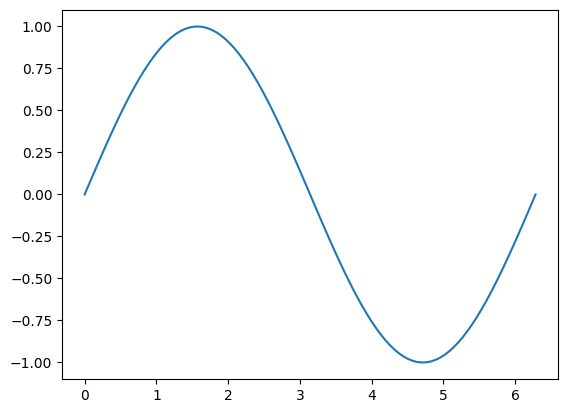

In [202]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

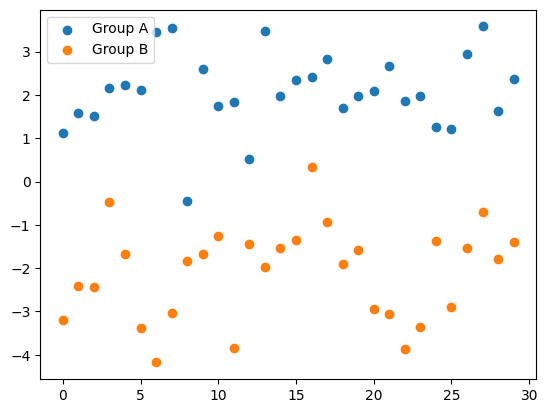

In [203]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()
x_axis = np.arange(30)
plt.scatter(x_axis, group_a, color="C0", label="Group A")
plt.scatter(x_axis, group_b, color="C1", label="Group B")

plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [204]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

Text(0.5, 1.0, 'Сирі дані (до тренування)')

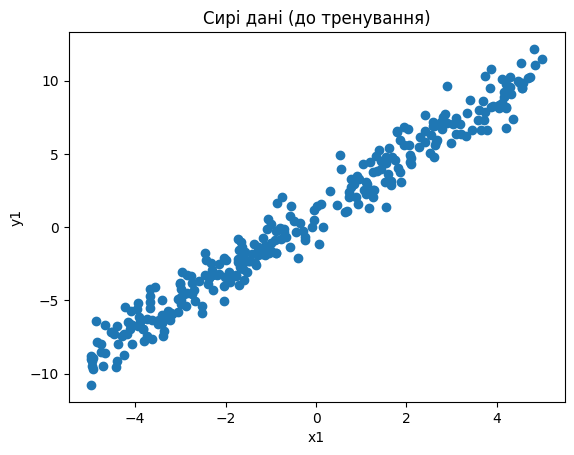

In [205]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1.flatten(), y1.flatten())
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [206]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...
indices = torch.randperm(TASK1_N)

train_size = int(0.70 * TASK1_N)
val_size = int(0.15 * TASK1_N)

train_indices = indices[:train_size]
val_indices = indices[train_size : train_size + val_size]
test_indices = indices[train_size + val_size:]

x_train1 = x1[train_indices]
y_train1 = y1[train_indices]

x_val1 = x1[val_indices]
y_val1 = y1[val_indices]

x_test1 = x1[test_indices]
y_test1 = y1[test_indices]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [207]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


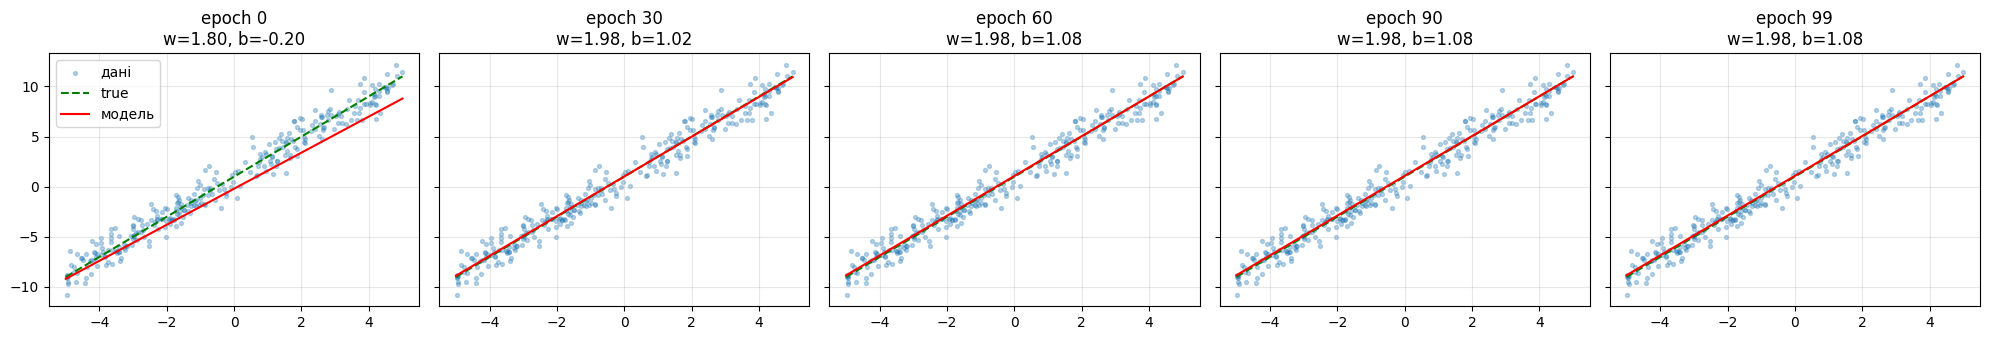

In [208]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій: вплив тривалості тренувань на рівень кортизолу (перетренерованість у спортзалі)
Змінні:
*   *x* - тривалість тренування в залі в год. діапазоном від 0.5 до 3.0 год
*   *y* - рівень вільного кортизолу в крові після тренування мкг/дл

Закладені параметри:

*   *b = 10.0* - базовий рівень кортизолу в крові людини у стані спокою
*   *w = 6.5* - швидкість зростання рівня стресу, кожна година навантаження додає 6.5 мкг/дл через виснаження.

Тренування до 1 години майже не несуть навантаження на ендокринну систему, а сесії понад 2-3 години дають значне підвищення гормону стресу в крові, сигналізуючи про втому.

Наявний гаусівський шум із середньоквадратичним відхиленням 1.5, тому що на рівень кортизолу впливають також індивідуальні фактори, так як: якість сну, харчування перед тренуванням, рівень кофеїну та психологічний стан.

In [209]:
import os
import pandas as pd
import torch

set_seed(42)

N = 300

training_hours = 0.5 + torch.rand(N, 1) * 3.0

true_w = 6.5
true_b = 10.0
noise = torch.randn(N, 1) * 1.5
cortisol_level = true_w * training_hours + true_b + noise

csv_path = os.path.join(ARTIFACT_DIR, "dataset.csv")
df = pd.DataFrame({
    "training_hours": training_hours.squeeze().numpy(),
    "cortisol_mcg_dl": cortisol_level.squeeze().numpy()
})
df.to_csv(csv_path, index=False)
print(f"Dataset is successfully saved into: {csv_path}")

indices = torch.randperm(N)

train_size = int(0.70 * N)
val_size = int(0.15 * N)

train_idx = indices[:train_size]
val_idx = indices[train_size : train_size + val_size]
test_idx = indices[train_size + val_size:]

X_train, y_train = training_hours[train_idx], cortisol_level[train_idx]
X_val, y_val = training_hours[val_idx], cortisol_level[val_idx]
X_test, y_test = training_hours[test_idx], cortisol_level[test_idx]

print(f"train/val/test: {len(X_train)}/{len(X_val)}/{len(X_test)}")

Dataset is successfully saved into: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
train/val/test: 210/45/45


In [210]:
def create_model():
    model = torch.nn.Linear(in_features=1, out_features=1)
    return model

def create_optimizer(model, lr=0.05):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    return optimizer

def train_cycle(model, optimizer, criterion, x_tr, y_tr, x_val, y_val, epochs=400):
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        loss = criterion(model(x_tr), y_tr)
        loss.backward()
        optimizer.step()

        if epoch % 100 == 0:
            model.eval()
            with torch.no_grad():
                val_loss = criterion(model(x_val), y_val)
            print(f"epoch {epoch:3d}, Train Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}")

    return model

def evaluate_model(model, criterion, x_test, y_test):
    model.eval()
    with torch.no_grad():
        test_loss = criterion(model(x_test), y_test)
    return test_loss.item()

criterion = torch.nn.MSELoss()

model = create_model()

optimizer = create_optimizer(model, lr=0.05)

print("start training...")
model = train_cycle(model, optimizer, criterion, X_train, y_train, X_val, y_val, epochs=400)

test_loss = evaluate_model(model, criterion, X_test, y_test)

print("-" * 40)
print(f"Final Test MSE: {test_loss:.4f}")

print(f"Found params: w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")

start training...
epoch 100, Train Loss: 2.2754, Val Loss: 3.1453
epoch 200, Train Loss: 1.9757, Val Loss: 2.5884
epoch 300, Train Loss: 1.9601, Val Loss: 2.5161
epoch 400, Train Loss: 1.9592, Val Loss: 2.5024
----------------------------------------
Final Test MSE: 2.6788
Found params: w = 6.616, b = 9.836


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [211]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(model.state_dict(), model_path)
print(f"Model saved to: {model_path}")

Model saved to: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [212]:
!pip install -q gradio
import gradio as gr
import torch
import os

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
model_path = os.path.join(ARTIFACT_DIR, "model.pt")
loaded_model.load_state_dict(torch.load(model_path))
loaded_model.eval()

def predict(hours):
    x_tensor = torch.tensor([[float(hours)]], dtype=torch.float32)
    with torch.no_grad():
        result = loaded_model(x_tensor).item()
    return round(result, 2)

app = gr.Interface(
    fn=predict,
    inputs=gr.Slider(minimum=0.5, maximum=4.0, step=0.5, label="Години тренування"),
    outputs=gr.Number(label="Рівень кортизолу"),
    flagging_mode="never"
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c4264b87987d385bf8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```